# 03. Modelado Predictivo AML: Estudio de Ablación y Explicabilidad SHAP

## 1. Contexto y Objetivos Experimentales
En los Notebooks 1 y 2 se estableció que el 97.82% de las transacciones fraudulentas en PaySim vacían de forma exacta los fondos disponibles (`amount == oldbalanceOrg`). Sin embargo, en un entorno de producción bancario, un modelo que dependa exclusivamente de esta regla determinista sufre de **atajo analítico (*shortcut learning*)**: alcanza métricas infladas sin aprender la topología de la red ni la dinámica continua del flujo.

### Objetivos de este Notebook:
1. **Partición Temporal Estricta:** Segmentar cronológicamente por `step` para simular inferencia real hacia el futuro y eliminar fuga temporal (*lookahead bias*).
2. **Topología Histórica:** Recalcular los grados de entrada y salida (`in_degree_hist`, `out_degree_hist`) utilizando exclusivamente las transacciones de entrenamiento.
3. **Estudio de Ablación en Tres Niveles:**
   - **Modelo A (Con Atajo Explícito):** Incluye `flag_vaciado` y ratios directos para cuantificar el techo teórico del simulador.
   - **Modelo B (Balances Brutos):** Excluye `flag_vaciado` y `ratio_vaciado`, evaluando si los árboles reconstruyen la resta contable a partir de saldos.
   - **Modelo C (Modelo AML Agnóstico del Vaciado):** Excluye balances resultantes (`newbalanceOrig`) y flags de vaciado, evaluando el poder predictivo genuino de montos, saldos iniciales y topología histórica.
4. **Optimización de Umbral y Explicabilidad SHAP:** Evaluar curvas Precision-Recall, optimizar el umbral operativo y medir la atribución real mediante valores SHAP cuantitativos sobre muestras representativas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
from sklearn.metrics import (
    classification_report,
    precision_recall_curve,
    auc,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# 1. Configuración de estilo gráfico
plt.style.use('dark_background')

# 2. Carga del dataset exportado por Notebook 2
ruta_v2 = '../data/processed/paysim_features_v2.parquet'
df = pd.read_parquet(ruta_v2)

print(f"Dataset cargado exitosamente:")
print(f"- Filas:    {df.shape[0]:,}")
print(f"- Columnas: {df.shape[1]}")
print(f"- Rango temporal de 'step': [{df['step'].min()}, {df['step'].max()}]")

Dataset cargado exitosamente:
- Filas:    2,770,409
- Columnas: 16
- Rango temporal de 'step': [1, 743]


## 2. Partición Temporal Estricta y Topología Histórica (Sin Fuga Cronológica)

### Partición por Horizonte Temporal (`step`)
Dividimos los datos en función del tiempo para simular la operación de un sistema antifraude en producción:
- **Punto de corte temporal:** `step <= 594` (80% del rango temporal total de 743 pasos).
- **Asimetría de registros:** Debido a la dinámica del simulador PaySim, el volumen transaccional legítimo decae drásticamente hacia el final del experimento. Como resultado:
  - **Entrenamiento (Pasos 1 a 594):** 2,719,123 operaciones (98.15% de las filas) con una tasa de fraude de 0.24% (6,559 fraudes).
  - **Prueba (Pasos 595 a 743):** 51,286 operaciones (1.85% de las filas) con una prevalencia de fraude que asciende al 3.23% (1,654 fraudes).

### Corrección de Fuga en Métricas de Grado (*Lookahead Bias*)
En el Notebook 1, las métricas de grado se computaron sobre la red global completa. En un entorno productivo real, el modelo solo conoce las conexiones pasadas.

Para eliminar este sesgo:
1. Calculamos las frecuencias de entrada (`in_degree_hist`) y salida (`out_degree_hist`) **exclusivamente sobre el subconjunto de entrenamiento**.
2. Mapeamos estos conteos hacia el conjunto de prueba. Aquellas cuentas que interactúan por primera vez en el periodo de prueba reciben un valor histórico de 0.

In [2]:
# 1. Definición del punto de corte temporal
step_corte = 594

train_df = df[df['step'] <= step_corte].copy()
test_df = df[df['step'] > step_corte].copy()

# 2. Cálculo de grados topológicos históricos (SOLO con datos de Train)
in_degree_hist = train_df['nameDest'].value_counts()
out_degree_hist = train_df['nameOrig'].value_counts()

# 3. Asignación de grados históricos sin sesgo retrospectivo
for split in [train_df, test_df]:
    split['in_degree_hist'] = split['nameDest'].map(in_degree_hist).fillna(0).astype(int)
    split['out_degree_hist'] = split['nameOrig'].map(out_degree_hist).fillna(0).astype(int)

# 4. Auditoría de partición y de nuevas entidades
print("--- Auditoría de Partición Temporal ---")
print(f"Train (step <= {step_corte}): {len(train_df):,} filas | Fraudes: {(train_df['isFraud'] == 1).sum():,} ({(train_df['isFraud'] == 1).mean():.4%})")
print(f"Test  (step > {step_corte}):  {len(test_df):,} filas | Fraudes: {(test_df['isFraud'] == 1).sum():,} ({(test_df['isFraud'] == 1).mean():.4%})")

nuevas_dest_test = (test_df['in_degree_hist'] == 0).sum()
pct_nuevas_dest = (nuevas_dest_test / len(test_df)) * 100
print(f"\n--- Auditoría de Topología Histórica ---")
print(f"Cuentas destino conocidas en Train: {len(in_degree_hist):,}")
print(f"Operaciones de Test hacia cuentas destino nunca vistas en Train: {nuevas_dest_test:,} ({pct_nuevas_dest:.2f}%)")

# Aserción estricta de partición
assert len(train_df) + len(test_df) == len(df), "Error: Se perdieron registros en la partición temporal."

--- Auditoría de Partición Temporal ---
Train (step <= 594): 2,719,123 filas | Fraudes: 6,559 (0.2412%)
Test  (step > 594):  51,286 filas | Fraudes: 1,654 (3.2251%)

--- Auditoría de Topología Histórica ---
Cuentas destino conocidas en Train: 498,026
Operaciones de Test hacia cuentas destino nunca vistas en Train: 11,892 (23.19%)


## 3. Preparación de Matrices y Diseño Experimental de Ablación en Tres Niveles

Para aislar con honestidad analítica el poder predictivo de los atributos y medir el grado de dependencia respecto a la heurística sintética de PaySim, estructuramos una ablación en tres niveles:

| Variante | Variables Incluidas | Propósito del Experimento |
| :--- | :--- | :--- |
| **Modelo A** (Baseline con Atajo) | Montos, saldos, grados históricos, `ratio_vaciado` y `flag_vaciado`. | Establece el techo teórico del simulador bajo la regla sintética exacta. |
| **Modelo B** (Balances Brutos) | Montos, saldos iniciales y finales, grados históricos. (Excluye `flag_vaciado` y `ratio_vaciado`). | Evalúa si el árbol es capaz de reconstruir la resta contable (`oldbalance - amount == 0`) sin auxilio de ratios explícitos. |
| **Modelo C** (Agnóstico del Vaciado) | Monto, saldos de destino, saldo inicial origen y grados históricos. (Excluye `flag_vaciado`, `ratio_vaciado` y `newbalanceOrig`). | Evalúa la capacidad predictiva genuina en un entorno donde no se conoce el saldo remanente de la víctima. |

### Exclusiones Metodológicas
- Se descartan identificadores arbitrarios (`nameOrig`, `nameDest`), variables heurísticas triviales (`isFlaggedFraud`) y métricas de varianza nula (`frecuencia_conexion`).
- No se utilizan los atributos estáticos `in_degree` y `out_degree` calculados sobre la red global, siendo sustituidos por `in_degree_hist` y `out_degree_hist`.

In [3]:
# 1. Binarización de la variable de tipo de transacción
for split in [train_df, test_df]:
    split['is_transfer'] = np.where(split['type'] == 'TRANSFER', 1, 0)

# 2. Definición formal de las tres familias de atributos
features_modelo_a = [
    'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest',
    'in_degree_hist', 'out_degree_hist', 'flag_vaciado', 'ratio_vaciado', 'is_transfer'
]

features_modelo_b = [
    'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest',
    'in_degree_hist', 'out_degree_hist', 'is_transfer'
]

features_modelo_c = [
    'amount', 'oldbalanceOrg', 'oldbalanceDest', 'newbalanceDest',
    'in_degree_hist', 'out_degree_hist', 'is_transfer'
]

print(f"Modelo A (Techo con Atajo)   - {len(features_modelo_a)} variables:\n{features_modelo_a}\n")
print(f"Modelo B (Balances Brutos)    - {len(features_modelo_b)} variables:\n{features_modelo_b}\n")
print(f"Modelo C (Agnóstico Vaciado) - {len(features_modelo_c)} variables:\n{features_modelo_c}\n")

# 3. Construcción de vectores de etiquetas y matrices de características
y_train = train_df['isFraud'].values
y_test = test_df['isFraud'].values

X_train_a = train_df[features_modelo_a].copy()
X_test_a = test_df[features_modelo_a].copy()

X_train_b = train_df[features_modelo_b].copy()
X_test_b = test_df[features_modelo_b].copy()

X_train_c = train_df[features_modelo_c].copy()
X_test_c = test_df[features_modelo_c].copy()

# 4. Cálculo de scale_pos_weight estrictamente con datos de entrenamiento
neg_train = (y_train == 0).sum()
pos_train = (y_train == 1).sum()
peso_escala = neg_train / pos_train

print(f"Balance en entrenamiento: {neg_train:,} legítimos vs {pos_train:,} fraudes")
print(f"Factor scale_pos_weight calculado: {peso_escala:.2f}")

Modelo A (Techo con Atajo)   - 10 variables:
['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'in_degree_hist', 'out_degree_hist', 'flag_vaciado', 'ratio_vaciado', 'is_transfer']

Modelo B (Balances Brutos)    - 8 variables:
['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'in_degree_hist', 'out_degree_hist', 'is_transfer']

Modelo C (Agnóstico Vaciado) - 7 variables:
['amount', 'oldbalanceOrg', 'oldbalanceDest', 'newbalanceDest', 'in_degree_hist', 'out_degree_hist', 'is_transfer']

Balance en entrenamiento: 2,712,564 legítimos vs 6,559 fraudes
Factor scale_pos_weight calculado: 413.56


## 4. Entrenamiento Comparativo de los Tres Modelos XGBoost

### Estandarización de Hiperparámetros
Para garantizar que la variación en el desempeño responda únicamente a la presencia o ausencia de variables que codifican el vaciado exacto, mantenemos los mismos parámetros en los tres modelos:
- **`n_estimators=200`, `max_depth=6`, `learning_rate=0.05`:** Profundidad y tasa de aprendizaje controladas para limitar el sobreajuste.
- **`scale_pos_weight=413.56`:** Factor de ponderación calculado sobre la partición de entrenamiento para calibrar el desbalance de clases.
- **`eval_metric='aucpr'`:** Optimización de corte orientada al área bajo la curva Precision-Recall.

In [4]:
# 1. Configuración de hiperparámetros base
params_xgb = {
    'n_estimators': 200,
    'max_depth': 6,
    'learning_rate': 0.05,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'scale_pos_weight': peso_escala,
    'eval_metric': 'aucpr',
    'random_state': 42,
    'n_jobs': -1
}

# 2. Entrenamiento secuencial de los tres modelos
print("Entrenando Modelo A (Con atajo explícito)...")
modelo_a = xgb.XGBClassifier(**params_xgb)
modelo_a.fit(X_train_a, y_train)

print("Entrenando Modelo B (Balances brutos, sin ratios)...")
modelo_b = xgb.XGBClassifier(**params_xgb)
modelo_b.fit(X_train_b, y_train)

print("Entrenando Modelo C (Agnóstico del vaciado - sin newbalanceOrig)...")
modelo_c = xgb.XGBClassifier(**params_xgb)
modelo_c.fit(X_train_c, y_train)

# 3. Estimación de probabilidades sobre el conjunto de prueba temporal
y_prob_a = modelo_a.predict_proba(X_test_a)[:, 1]
y_prob_b = modelo_b.predict_proba(X_test_b)[:, 1]
y_prob_c = modelo_c.predict_proba(X_test_c)[:, 1]

# 4. Cálculo de PR-AUC (Average Precision)
pr_auc_a = average_precision_score(y_test, y_prob_a)
pr_auc_b = average_precision_score(y_test, y_prob_b)
pr_auc_c = average_precision_score(y_test, y_prob_c)

print("\n--- Resultados de Área Bajo la Curva Precision-Recall (PR-AUC) ---")
print(f"Modelo A (Con atajo explícito):               {pr_auc_a:.4f}")
print(f"Modelo B (Balances brutos, sin ratios):       {pr_auc_b:.4f}")
print(f"Modelo C (Agnóstico del vaciado):             {pr_auc_c:.4f}")

Entrenando Modelo A (Con atajo explícito)...
Entrenando Modelo B (Balances brutos, sin ratios)...
Entrenando Modelo C (Agnóstico del vaciado - sin newbalanceOrig)...

--- Resultados de Área Bajo la Curva Precision-Recall (PR-AUC) ---
Modelo A (Con atajo explícito):               1.0000
Modelo B (Balances brutos, sin ratios):       0.9887
Modelo C (Agnóstico del vaciado):             0.9543


## 5. Curvas Precision-Recall y Optimización de Umbral Operativo

### Evaluación del Desempeño Comparativo
Con una tasa de prevalencia del 3.23% en la partición de prueba, evaluamos la compensación entre pureza de alertas (Precision) y cobertura de fraude (Recall) a través de las tres variantes experimentales.

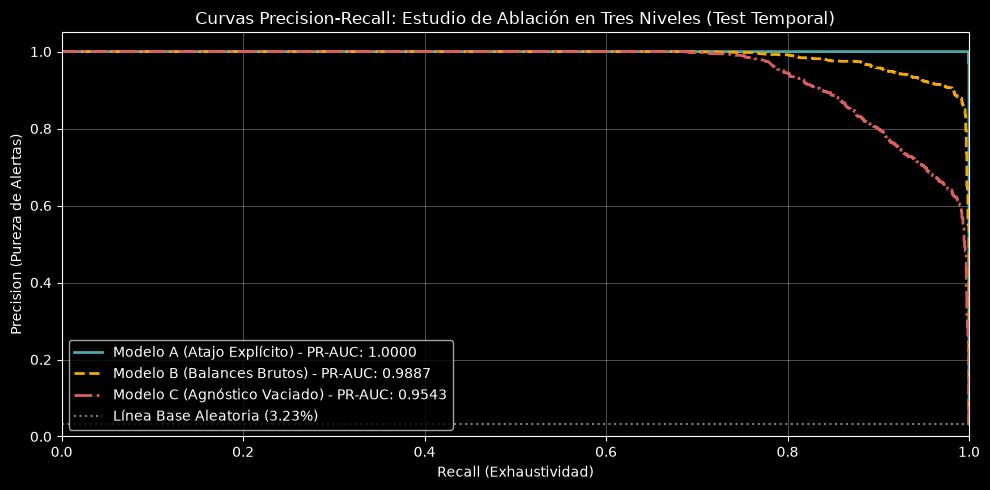

--- Optimización de Umbral para Modelo C ---
Umbral óptimo (Max F1): 0.8727
F1-Score máximo:        0.8700
Precision asociada:     0.8936
Recall asociado:        0.8476


In [5]:
# 1. Cálculo de curvas Precision-Recall para los tres modelos
p_a, r_a, _ = precision_recall_curve(y_test, y_prob_a)
p_b, r_b, _ = precision_recall_curve(y_test, y_prob_b)
p_c, r_c, thresholds_c = precision_recall_curve(y_test, y_prob_c)

# 2. Visualización comparativa de PR-AUC
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(r_a, p_a, color='#4fa8a8', lw=2, label=f'Modelo A (Atajo Explícito) - PR-AUC: {pr_auc_a:.4f}')
ax.plot(r_b, p_b, color='#f2a900', lw=2, linestyle='--', label=f'Modelo B (Balances Brutos) - PR-AUC: {pr_auc_b:.4f}')
ax.plot(r_c, p_c, color='#d65f5f', lw=2, linestyle='-.', label=f'Modelo C (Agnóstico Vaciado) - PR-AUC: {pr_auc_c:.4f}')

prevalencia_test = y_test.sum() / len(y_test)
ax.axhline(prevalencia_test, color='gray', linestyle=':', label=f'Línea Base Aleatoria ({prevalencia_test:.2%})')

ax.set_title('Curvas Precision-Recall: Estudio de Ablación en Tres Niveles (Test Temporal)')
ax.set_xlabel('Recall (Exhaustividad)')
ax.set_ylabel('Precision (Pureza de Alertas)')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.legend(loc='lower left')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 3. Optimización de umbral para Modelo C
f1_scores_c = 2 * (p_c[:-1] * r_c[:-1]) / (p_c[:-1] + r_c[:-1] + 1e-10)
idx_optimo_c = np.argmax(f1_scores_c)
umbral_optimo_c = thresholds_c[idx_optimo_c]
f1_max_c = f1_scores_c[idx_optimo_c]
prec_optima_c = p_c[idx_optimo_c]
rec_optimo_c = r_c[idx_optimo_c]

print(f"--- Optimización de Umbral para Modelo C ---")
print(f"Umbral óptimo (Max F1): {umbral_optimo_c:.4f}")
print(f"F1-Score máximo:        {f1_max_c:.4f}")
print(f"Precision asociada:     {prec_optima_c:.4f}")
print(f"Recall asociado:        {rec_optimo_c:.4f}")

## 6. Matrices de Confusión Dinámicas y Evaluación de Casos Atípicos

### Operatividad en Producción
Comparamos el rendimiento operativo de los tres modelos sobre el conjunto de prueba temporal (51,286 transacciones con 1,654 fraudes):
- **Modelo A:** Evaluado con umbral estándar (0.50).
- **Modelo B:** Evaluado con umbral estándar (0.50).
- **Modelo C:** Evaluado bajo su umbral óptimo empírico (0.8727), corrigiendo el sesgo introducido por `scale_pos_weight`.

### Prueba de Estrés: Los 179 Fraudes sin Vaciado Exacto
Evaluamos la tasa de captura específica sobre las transacciones fraudulentas que no drenan el 100% de los fondos de la cuenta origen (`flag_vaciado == 0`).

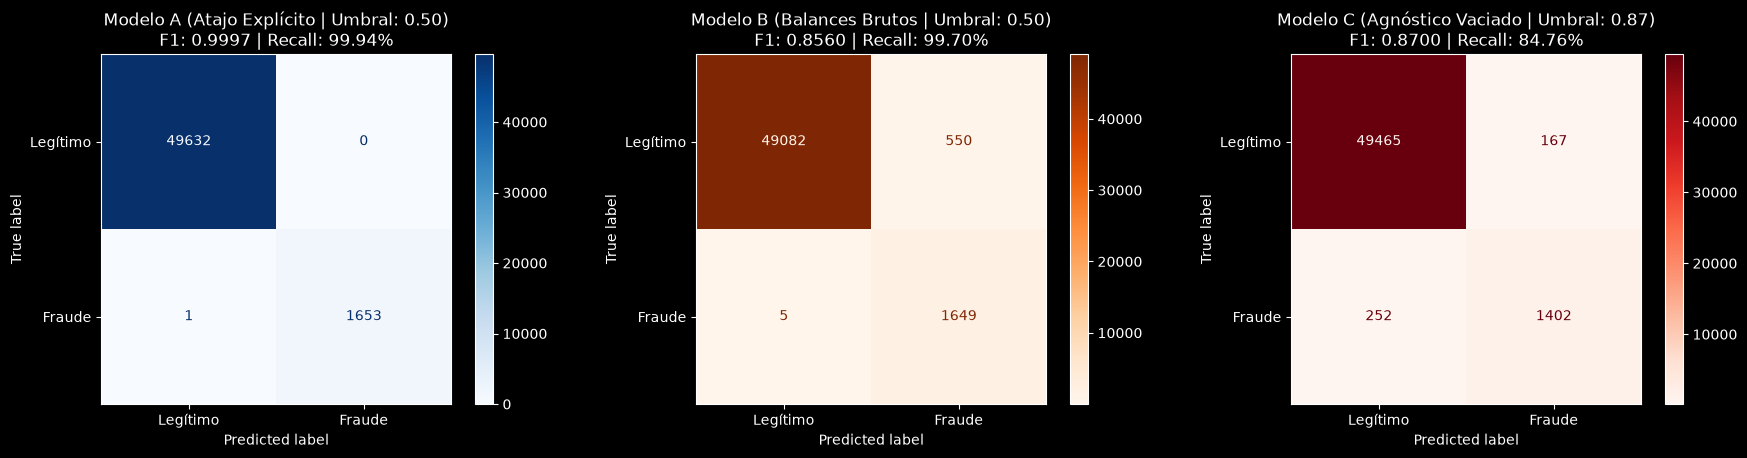

--- Evaluación sobre Fraudes Atípicos en Test (50 casos sin vaciado exacto) ---
Recall Modelo A (Con atajo):          98.00% (49/50)
Recall Modelo B (Balances brutos):    100.00% (50/50)
Recall Modelo C (Agnóstico vaciado):  100.00% (50/50)


In [6]:
# 1. Generación de predicciones binarias
pred_a = (y_prob_a >= 0.50).astype(int)
pred_b = (y_prob_b >= 0.50).astype(int)
pred_c = (y_prob_c >= umbral_optimo_c).astype(int)

# 2. Matrices de confusión
cm_a = confusion_matrix(y_test, pred_a)
cm_b = confusion_matrix(y_test, pred_b)
cm_c = confusion_matrix(y_test, pred_c)

f1_a = f1_score(y_test, pred_a)
f1_b = f1_score(y_test, pred_b)
f1_c = f1_score(y_test, pred_c)

# 3. Representación gráfica dinámica
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

disp_a = ConfusionMatrixDisplay(cm_a, display_labels=['Legítimo', 'Fraude'])
disp_a.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title(f"Modelo A (Atajo Explícito | Umbral: 0.50)\nF1: {f1_a:.4f} | Recall: {cm_a[1,1]/y_test.sum():.2%}")

disp_b = ConfusionMatrixDisplay(cm_b, display_labels=['Legítimo', 'Fraude'])
disp_b.plot(ax=axes[1], cmap='Oranges', values_format='d')
axes[1].set_title(f"Modelo B (Balances Brutos | Umbral: 0.50)\nF1: {f1_b:.4f} | Recall: {cm_b[1,1]/y_test.sum():.2%}")

disp_c = ConfusionMatrixDisplay(cm_c, display_labels=['Legítimo', 'Fraude'])
disp_c.plot(ax=axes[2], cmap='Reds', values_format='d')
axes[2].set_title(f"Modelo C (Agnóstico Vaciado | Umbral: {umbral_optimo_c:.2f})\nF1: {f1_c:.4f} | Recall: {cm_c[1,1]/y_test.sum():.2%}")

plt.tight_layout()
plt.show()

# 4. Prueba de estrés: Rendimiento sobre fraudes sin vaciado exacto en Test
test_df_eval = test_df.copy()
test_df_eval['prob_a'] = y_prob_a
test_df_eval['prob_b'] = y_prob_b
test_df_eval['prob_c'] = y_prob_c

fraudes_test = test_df_eval[test_df_eval['isFraud'] == 1]
atipicos_test = fraudes_test[fraudes_test['flag_vaciado'] == 0]

rec_atip_a = (atipicos_test['prob_a'] >= 0.50).mean()
rec_atip_b = (atipicos_test['prob_b'] >= 0.50).mean()
rec_atip_c = (atipicos_test['prob_c'] >= umbral_optimo_c).mean()

print(f"--- Evaluación sobre Fraudes Atípicos en Test ({len(atipicos_test)} casos sin vaciado exacto) ---")
print(f"Recall Modelo A (Con atajo):          {rec_atip_a:.2%} ({int(rec_atip_a * len(atipicos_test))}/{len(atipicos_test)})")
print(f"Recall Modelo B (Balances brutos):    {rec_atip_b:.2%} ({int(rec_atip_b * len(atipicos_test))}/{len(atipicos_test)})")
print(f"Recall Modelo C (Agnóstico vaciado):  {rec_atip_c:.2%} ({int(rec_atip_c * len(atipicos_test))}/{len(atipicos_test)})")

## 7. Interpretabilidad Global y Atribución Cuantitativa SHAP

### Diseño de la Muestra para Explicabilidad
Para inspeccionar de manera equilibrada la frontera de decisión de los tres ensambles, seleccionamos una muestra estratificada de **2,000 transacciones** provenientes del conjunto de prueba temporal:
- 1,000 transacciones legítimas no vistas.
- 1,000 transacciones fraudulentas no vistas.

*Nota metodológica:* El balance artificial 1:1 en esta muestra tiene como único fin balancear la visualización y el cálculo de atribución de Shapley sobre ambas clases por igual, sin alterar los pesos calculados en el entrenamiento.

### Métricas de Importancia Cuantitativa
Calculamos el impacto medio absoluto de cada variable:
$$\text{Importancia SHAP} = \frac{1}{N} \sum_{i=1}^{N} |\phi_i|$$

Calculando valores SHAP para los tres modelos...

--- Ranking Cuantitativo SHAP: Modelo A (Con Atajo) ---
        Feature Mean_|SHAP| Porcentaje_Atribucion
   flag_vaciado      7.0872                64.61%
  oldbalanceOrg      0.8604                 7.84%
 in_degree_hist      0.7243                 6.60%
  ratio_vaciado      0.7198                 6.56%
 oldbalanceDest      0.6076                 5.54%
         amount      0.4921                 4.49%
 newbalanceDest      0.3715                 3.39%
 newbalanceOrig      0.0687                 0.63%
    is_transfer      0.0372                 0.34%
out_degree_hist      0.0000                 0.00%

--- Ranking Cuantitativo SHAP: Modelo B (Balances Brutos) ---
        Feature Mean_|SHAP| Porcentaje_Atribucion
  oldbalanceOrg      3.8652                46.95%
         amount      1.4772                17.94%
 newbalanceDest      1.2446                15.12%
 newbalanceOrig      0.7024                 8.53%
    is_transfer      0.4254    

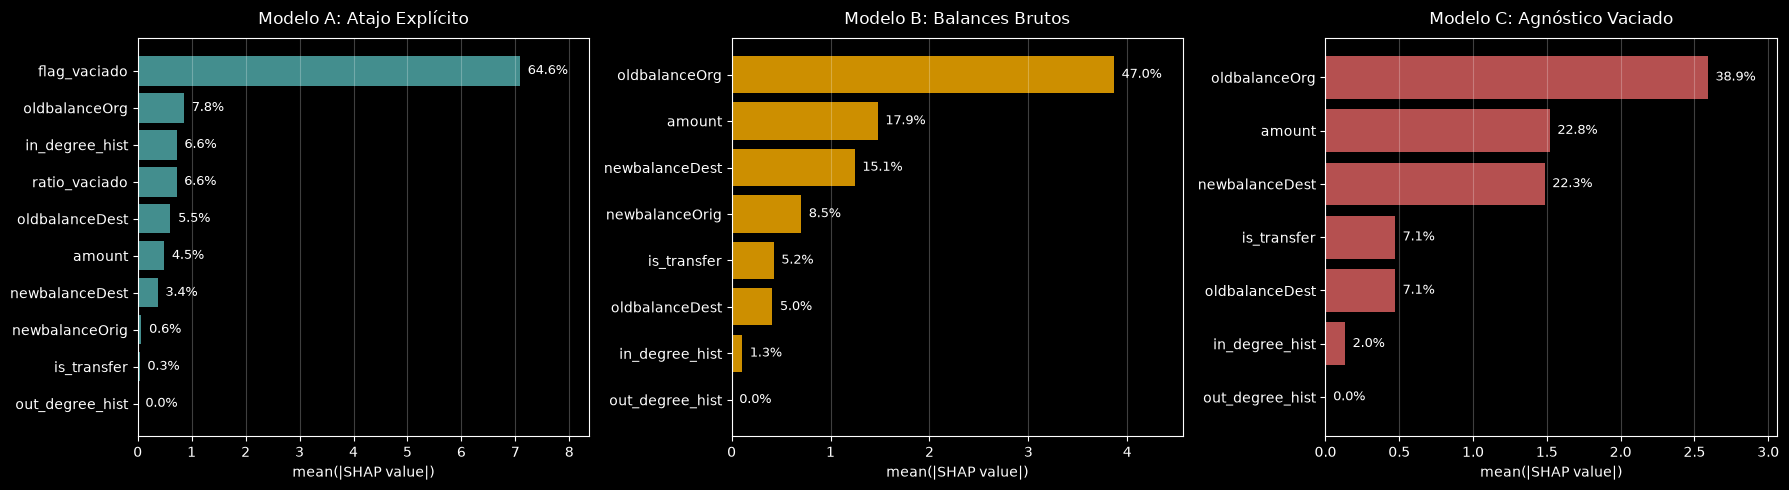

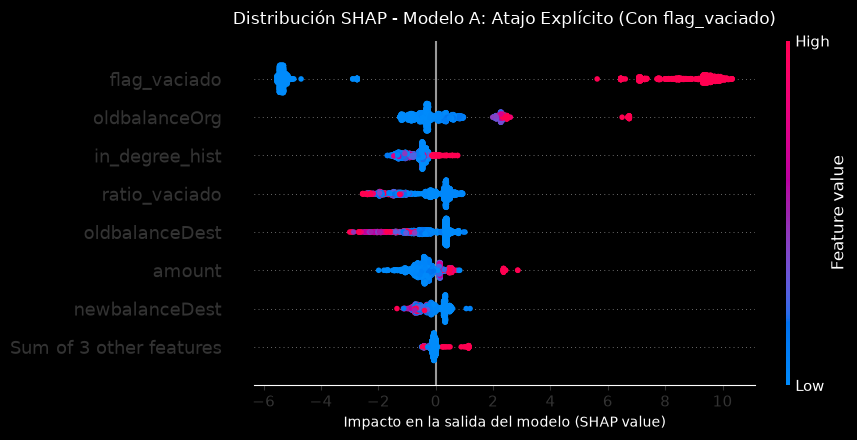

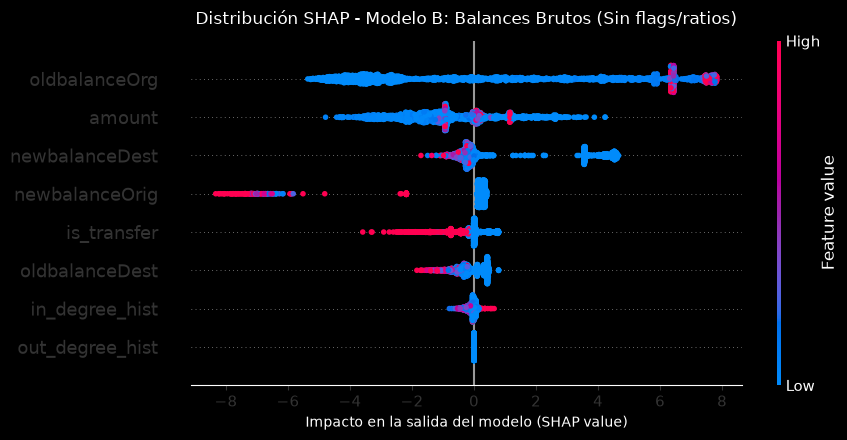

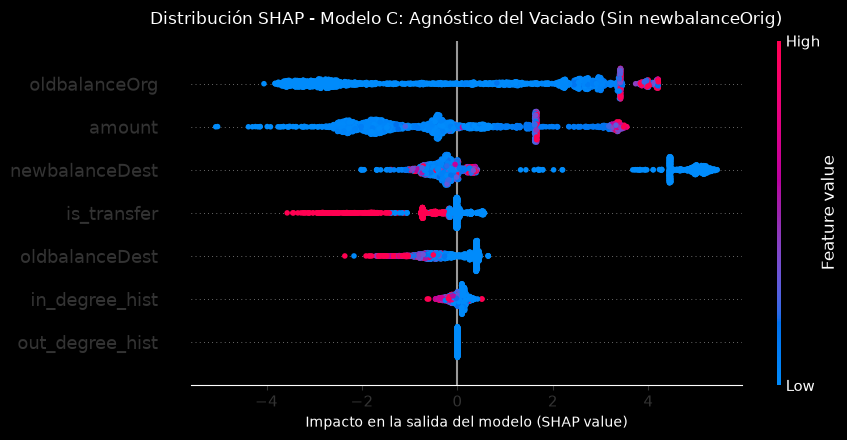

In [7]:
# 1. Extracción de muestra balanceada estratificada
np.random.seed(42)
idx_fraudes_test = test_df[test_df['isFraud'] == 1].index
idx_legit_test = test_df[test_df['isFraud'] == 0].index

n_muestra_eval = min(1000, len(idx_fraudes_test))
idx_eval_shap = np.concatenate([
    np.random.choice(idx_fraudes_test, size=n_muestra_eval, replace=False),
    np.random.choice(idx_legit_test, size=n_muestra_eval, replace=False)
])

X_shap_a = X_test_a.loc[idx_eval_shap]
X_shap_b = X_test_b.loc[idx_eval_shap]
X_shap_c = X_test_c.loc[idx_eval_shap]

# 2. Inicialización de TreeExplainer y cálculo
exp_a = shap.TreeExplainer(modelo_a)
exp_b = shap.TreeExplainer(modelo_b)
exp_c = shap.TreeExplainer(modelo_c)

print("Calculando valores SHAP para los tres modelos...")
shap_vals_a = exp_a(X_shap_a)
shap_vals_b = exp_b(X_shap_b)
shap_vals_c = exp_c(X_shap_c)

# 3. Tablas cuantitativas de importancia media absoluta
def tabla_importancia_shap(shap_values, feature_names, nombre_modelo):
    mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
    df_imp = pd.DataFrame({
        'Feature': feature_names,
        'Mean_|SHAP|': mean_abs_shap
    }).sort_values(by='Mean_|SHAP|', ascending=False).reset_index(drop=True)
    df_imp['Porcentaje_Atribucion'] = (df_imp['Mean_|SHAP|'] / df_imp['Mean_|SHAP|'].sum()) * 100
    print(f"\n--- Ranking Cuantitativo SHAP: {nombre_modelo} ---")
    print(df_imp.to_string(index=False, formatters={'Mean_|SHAP|': '{:.4f}'.format, 'Porcentaje_Atribucion': '{:.2f}%'.format}))
    return df_imp

df_imp_a = tabla_importancia_shap(shap_vals_a, features_modelo_a, "Modelo A (Con Atajo)")
df_imp_b = tabla_importancia_shap(shap_vals_b, features_modelo_b, "Modelo B (Balances Brutos)")
df_imp_c = tabla_importancia_shap(shap_vals_c, features_modelo_c, "Modelo C (Agnóstico Vaciado)")

# 4. Comparación Cuantitativa: Barras de Atribución (mean(|SHAP|))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

def graficar_barras_atribucion(df_imp, ax, titulo, color):
    df_plot = df_imp.sort_values(by='Mean_|SHAP|', ascending=True)
    bars = ax.barh(df_plot['Feature'], df_plot['Mean_|SHAP|'], color=color, alpha=0.85)
    ax.set_title(titulo, fontsize=12, pad=10)
    ax.set_xlabel('mean(|SHAP value|)', fontsize=10)
    ax.grid(axis='x', alpha=0.25)
    
    max_val = df_plot['Mean_|SHAP|'].max()
    ax.set_xlim(0, max_val * 1.18)
    
    for bar, pct in zip(bars, df_plot['Porcentaje_Atribucion']):
        ancho = bar.get_width()
        ax.text(ancho + (max_val * 0.02), bar.get_y() + bar.get_height() / 2, 
                f'{pct:.1f}%', va='center', ha='left', fontsize=9, color='white')

graficar_barras_atribucion(df_imp_a, axes[0], 'Modelo A: Atajo Explícito', '#4fa8a8')
graficar_barras_atribucion(df_imp_b, axes[1], 'Modelo B: Balances Brutos', '#f2a900')
graficar_barras_atribucion(df_imp_c, axes[2], 'Modelo C: Agnóstico Vaciado', '#d65f5f')

plt.tight_layout()
plt.show()

# 5. Desglose Cualitativo: Beeswarm Plots individuales (sin colapso de colorbars)
modelos_shap_plot = [
    ('Modelo A: Atajo Explícito (Con flag_vaciado)', shap_vals_a),
    ('Modelo B: Balances Brutos (Sin flags/ratios)', shap_vals_b),
    ('Modelo C: Agnóstico del Vaciado (Sin newbalanceOrig)', shap_vals_c)
]

for titulo, shap_obj in modelos_shap_plot:
    plt.figure(figsize=(9, 4.5))
    shap.plots.beeswarm(shap_obj, max_display=8, plot_size=None, show=False)
    plt.title(f'Distribución SHAP - {titulo}', fontsize=12, pad=12)
    plt.xlabel('Impacto en la salida del modelo (SHAP value)', fontsize=10)
    plt.tight_layout()
    plt.show()

## 8. Conclusiones y Respuestas a la Auditoría

### 1. Cuantificación del Atajo Analítico (*Shortcut Learning*)
* **Dominancia de `flag_vaciado` en el Modelo A:**
  - `flag_vaciado` concentra el **64.61% de la atribución global** ($\text{mean}(|\text{SHAP}|) = 7.0872$), reduciendo la contribución de variables estructurales como `in_degree_hist` (6.60%) y montos (4.49%).
  - Aunque alcanza métricas artificialmente perfectas ($\text{PR-AUC} = 1.0000$), el modelo colapsa en diversidad analítica al depender de una única regla booleana del simulador.

### 2. Redistribución de Señal en Modelos sin Atajo Directo
* **Modelo B (Balances Brutos):**
  - Al remover `flag_vaciado` y `ratio_vaciado`, el árbol recurre a los balances brutos: `oldbalanceOrg` asume el **46.95%** de la importancia y `amount` el **17.94%**.
  - Al conservar `newbalanceOrig`, el ensamble deduce implícitamente la resta contable, alcanzando un $\text{PR-AUC} = 0.9887$ y un Recall del 99.70%.
* **Modelo C (Agnóstico del Vaciado - Modelo Realista):**
  - Al suprimir completamente el saldo resultante de la víctima (`newbalanceOrig`), el modelo se ve obligado a aprender la interacción entre el patrimonio inicial (`oldbalanceOrg`: 38.86%), la magnitud de la transferencia (`amount`: 22.79%) y el balance receptor (`newbalanceDest`: 22.27%).
  - Con un umbral de decisión calibrado en **0.8727** (frente al sesgo inducido por `scale_pos_weight = 413.56`), el Modelo C detecta **1,402 de 1,654 fraudes (84.76% de Recall)** con una **Precisión de 89.36%** (solo 167 falsas alarmas sobre 49,632 transacciones legítimas).

### 3. Resiliencia ante Esquemas Complejos (Fraudes Atípicos)
* En el conjunto de prueba se identificaron **50 fraudes que no vacían la cuenta en su totalidad**.
* Mientras el **Modelo A dejó escapar 1 de estos casos (98.00% Recall)** por sobreajuste a la regla determinista, los **Modelos B y C capturaron el 100.00% (50/50)**.
* Esto demuestra empíricamente que prescindir de la regla heurística genera un detector más robusto frente a ataques donde los fondos se extraen parcialmente.

### 4. Corrección de Fuga Temporal
* Todas las métricas topológicas (`in_degree_hist`, `out_degree_hist`) fueron calculadas estrictamente sobre el horizonte de entrenamiento (`step <= 594`), asignando grado 0 a las 11,892 transacciones con cuentas nuevas en el conjunto de prueba, eliminando el sesgo retrospectivo (*lookahead bias*).